### Preparing the dataset

- order_id identifies a transaction.
- product_name identifies the purchased product.
We already have integrated_prior.parquet, which contains these columns.

### Import libraries and Define the file paths

In [1]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path
import time

INTEGRATED_DIR = Path("../outputs/integrated_data")

integrated_path = (
    INTEGRATED_DIR / "integrated_prior.parquet"
).resolve().as_posix()

con = duckdb.connect()

print("Integrated file exists:", Path(integrated_path).exists())

Integrated file exists: True


inspecting dataset

In [2]:
con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_parquet('{integrated_path}')
""").df()

,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,user_id,BIGINT,YES,None,None,None
2,order_number,BIGINT,YES,None,None,None
3,product_id,BIGINT,YES,None,None,None
4,reordered,BIGINT,YES,None,None,None
5,product_name,VARCHAR,YES,None,None,None
6,aisle_id,BIGINT,YES,None,None,None
7,department_id,BIGINT,YES,None,None,None


### Create transaction baskets

In [3]:
transactions_path = (
    INTEGRATED_DIR / "transactions.parquet"
).resolve().as_posix()

con.execute(f"""
    COPY (
        SELECT
            order_id,
            LIST(DISTINCT product_name ORDER BY product_name) AS products
        FROM read_parquet('{integrated_path}')
        GROUP BY order_id
    )
    TO '{transactions_path}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Transaction dataset created successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Transaction dataset created successfully!


In [4]:
transactions_df = pd.read_parquet(transactions_path)

print("Dataset shape:", transactions_df.shape)

display(transactions_df.head())

Dataset shape: (3214874, 2)


,order_id,products
0,4068,"[Black Truffle Oil, Holler Mountain Organic Co..."
1,5923,"[1% Lowfat Milk, Bag of Organic Bananas, Baris..."
2,9947,"[50/50 Spring Mix & Baby Spinach, Aged White C..."
3,406575,"[All Natural Marinara Pasta Sauce, Organic Fuj..."
4,408205,[Berry Berry Good Lemonade Organic Juice Drink...


Check transaction sizes

It helps us understand the size of grocery baskets and plan the mining process.

In [5]:
transactions_df["basket_size"] = transactions_df["products"].apply(len)

print("Average basket size:", transactions_df["basket_size"].mean())
print("Minimum basket size:", transactions_df["basket_size"].min())
print("Maximum basket size:", transactions_df["basket_size"].max())

display(transactions_df["basket_size"].describe())

Average basket size: 10.088883421247614
Minimum basket size: 1
Maximum basket size: 145


count    3.214874e+06
mean     1.008888e+01
std      7.525398e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.450000e+02
Name: basket_size, dtype: float64

### Select a sample for algorithm comparison

In [8]:
transactions_sample = transactions_df.sample(
    n=50000,
    random_state=42
).copy()

print("Sample shape:", transactions_sample.shape)

Sample shape: (50000, 3)


### Prepare transaction lists

In [9]:
transactions_list = transactions_sample["products"].tolist()

print("Total transactions:", len(transactions_list))
print("First transaction:", transactions_list[0])
print("Products in first transaction:", len(transactions_list[0]))

Total transactions: 50000
First transaction: ['All Purpose Flour' 'Chewy Fudge Brownie Mix' 'Corn Flakes'
 'Cut & Peeled Baby Carrots' 'Fettuccine' 'Gluten Free Rice Chex'
 'Golden Brown Pure Cane Sugar' 'Hass Avocado Bag' 'Mini Bagels'
 'Multi Grain Cheerios' 'Pure Cane Granulated White Sugar'
 'Rice Pilaf Mix' 'Thin Spaghetti Pasta']
Products in first transaction: 13


[['Milk', 'Bread', 'Butter'], ['Milk', 'Eggs'], ['Bread', 'Butter']]

### Prepare data for Apriori and FP-Growth

We convert each transaction into a table where:
- 1 means the product is present in the transaction.
- 0 means the product is absent.

In [12]:
from mlxtend.preprocessing import TransactionEncoder

encoder = TransactionEncoder()

encoded_array = encoder.fit(transactions_list).transform(
    transactions_list,
    sparse=True
)

basket_df = pd.DataFrame.sparse.from_spmatrix(
    encoded_array,
    columns=encoder.columns_
)

print("Encoded dataset shape:", basket_df.shape)
print("Storage format:", type(encoded_array))
display(basket_df.head())


Encoded dataset shape: (50000, 29238)
Storage format: <class 'scipy.sparse._csr.csr_matrix'>


,#2 Coffee Filters,#4 Natural Brown Coffee Filters,0 Calorie Acai Raspberry Water Beverage,0 Calorie Fuji Apple Pear Water Beverage,0 Calorie Strawberry Dragonfruit Water Beverage,0% Fat Black Cherry Greek Yogurt y,0% Fat Blueberry Greek Yogurt,0% Fat Free Organic Milk,0% Fat Greek Yogurt Black Cherry on the Bottom,0% Fat Greek Yogurt Vanilla,...,with Color Safe Brightener Power Paks 2in1 Stain Fighter,with Crispy Almonds Cereal,with Dawn Action Pacs Fresh Scent Dishwasher Detergent Pacs,with Olive Oil Mayonnaise,with Olive Oil Mayonnaise Dressing,with Xylitol Cinnamon 18 Sticks Sugar Free Gum,with Xylitol Island Berry Lime 18 Sticks Sugar Free Gum,with Xylitol Original Flavor 18 Sticks Sugar Free Gum,with Xylitol Watermelon Twist 18 Sticks Sugar Free Gum,with a Splash of Mango Coconut Water
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [13]:
min_support = 0.01

print("Minimum Support:", min_support)
print("Minimum transaction count:", int(min_support * len(transactions_list)))


Minimum Support: 0.01
Minimum transaction count: 500


## Apply the Apriori algorithm


In [14]:
from mlxtend.frequent_patterns import apriori

start_time = time.time()

frequent_itemsets_apriori = apriori(
    basket_df,
    min_support=min_support,
    use_colnames=True
)

apriori_time = time.time() - start_time

print("Apriori execution time:", round(apriori_time, 2), "seconds")
print("Total frequent itemsets:", len(frequent_itemsets_apriori))

display(frequent_itemsets_apriori.head(10))

Apriori execution time: 2.59 seconds
Total frequent itemsets: 114


,support,itemsets
0,0.01164,frozenset({100% Raw Coconut Water})
1,0.01878,frozenset({100% Whole Wheat Bread})
2,0.01170,frozenset({2% Reduced Fat Milk})
3,0.02580,frozenset({Apple Honeycrisp Organic})
4,0.02048,frozenset({Asparagus})
5,0.12038,frozenset({Bag of Organic Bananas})
6,0.14792,frozenset({Banana})
7,0.01120,frozenset({Bartlett Pears})
8,0.01776,frozenset({Blueberries})
9,0.01492,frozenset({Boneless Skinless Chicken Breasts})


Check itemset sizes

In [15]:
frequent_itemsets_apriori["itemset_size"] = (
    frequent_itemsets_apriori["itemsets"].apply(len)
)

print(
    frequent_itemsets_apriori["itemset_size"]
    .value_counts()
    .sort_index()
)

itemset_size
1    101
2     13
Name: count, dtype: int64


#### Display frequent product pairs

In [16]:
frequent_pairs = frequent_itemsets_apriori[
    frequent_itemsets_apriori["itemset_size"] == 2
].sort_values(
    by="support",
    ascending=False
)

display(frequent_pairs)

,support,itemsets,itemset_size
104,0.01942,"frozenset({Bag of Organic Bananas, Organic Str...",2
102,0.01894,"frozenset({Organic Hass Avocado, Bag of Organi...",2
108,0.01864,"frozenset({Banana, Organic Strawberries})",2
106,0.01716,"frozenset({Banana, Organic Avocado})",2
107,0.01644,"frozenset({Banana, Organic Baby Spinach})",2
101,0.01578,"frozenset({Bag of Organic Bananas, Organic Bab...",2
109,0.01296,"frozenset({Banana, Strawberries})",2
103,0.01280,"frozenset({Bag of Organic Bananas, Organic Ras...",2
105,0.01246,"frozenset({Banana, Large Lemon})",2
112,0.01246,"frozenset({Organic Hass Avocado, Organic Straw...",2


### Generate Association Rules using Apriori.

In [17]:
from mlxtend.frequent_patterns import association_rules

rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.1
)

print("Total association rules:", len(rules_apriori))

display(
    rules_apriori[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values(
        by="lift",
        ascending=False
    ).head(10)
)

Total association rules: 24


,antecedents,consequents,support,confidence,lift
22,frozenset({Organic Raspberries}),frozenset({Organic Strawberries}),0.01036,0.239926,2.863761
23,frozenset({Organic Strawberries}),frozenset({Organic Raspberries}),0.01036,0.123657,2.863761
5,frozenset({Organic Raspberries}),frozenset({Bag of Organic Bananas}),0.01280,0.296434,2.462482
4,frozenset({Bag of Organic Bananas}),frozenset({Organic Raspberries}),0.01280,0.106330,2.462482
3,frozenset({Bag of Organic Bananas}),frozenset({Organic Hass Avocado}),0.01894,0.157335,2.381700
2,frozenset({Organic Hass Avocado}),frozenset({Bag of Organic Bananas}),0.01894,0.286709,2.381700
20,frozenset({Organic Hass Avocado}),frozenset({Organic Strawberries}),0.01246,0.188616,2.251330
21,frozenset({Organic Strawberries}),frozenset({Organic Hass Avocado}),0.01246,0.148723,2.251330
16,frozenset({Organic Hass Avocado}),frozenset({Organic Baby Spinach}),0.01052,0.159249,2.151434
17,frozenset({Organic Baby Spinach}),frozenset({Organic Hass Avocado}),0.01052,0.142124,2.151434


In [18]:
apriori_summary = {
    "Algorithm": "Apriori",
    "Execution Time (seconds)": round(apriori_time, 2),
    "Frequent Itemsets": len(frequent_itemsets_apriori),
    "Association Rules": len(rules_apriori)
}

print(apriori_summary)

{'Algorithm': 'Apriori', 'Execution Time (seconds)': 2.59, 'Frequent Itemsets': 114, 'Association Rules': 24}


# Implement FP-Growth

In [19]:
from mlxtend.frequent_patterns import fpgrowth

start_time = time.time()

frequent_itemsets_fp = fpgrowth(
    basket_df,
    min_support=min_support,
    use_colnames=True
)

fp_growth_time = time.time() - start_time

print("FP-Growth execution time:", round(fp_growth_time, 2), "seconds")
print("Total frequent itemsets:", len(frequent_itemsets_fp))

display(frequent_itemsets_fp.head(10))

FP-Growth execution time: 4.97 seconds
Total frequent itemsets: 114


,support,itemsets
0,0.01062,frozenset({Whole Milk})
1,0.02046,frozenset({Organic Blackberries})
2,0.14792,frozenset({Banana})
3,0.06606,frozenset({Organic Hass Avocado})
4,0.04610,frozenset({Strawberries})
5,0.04318,frozenset({Organic Raspberries})
6,0.02632,frozenset({Seedless Red Grapes})
7,0.02406,frozenset({Organic Half & Half})
8,0.01274,frozenset({Grape White/Green Seedless})
9,0.12038,frozenset({Bag of Organic Bananas})


Verify both algorithms found identical itemsets

In [20]:
apriori_results = frequent_itemsets_apriori[
    ["support", "itemsets"]
].sort_values("itemsets").reset_index(drop=True)

fp_results = frequent_itemsets_fp[
    ["support", "itemsets"]
].sort_values("itemsets").reset_index(drop=True)

print(
    "Same itemsets:",
    set(apriori_results["itemsets"]) == set(fp_results["itemsets"])
)

print(
    "Same support values:",
    apriori_results["support"].round(10).equals(
        fp_results["support"].round(10)
    )
)

Same itemsets: True
Same support values: False


### Confirm support equality

In [22]:
print(
    "Maximum support difference:",
    comparison["support_difference"].max()
)

print(
    "Number of itemsets with different support:",
    (comparison["support_difference"] > 1e-10).sum()
)

Maximum support difference: 0.0
Number of itemsets with different support: 0


### Generate FP-Growth Association Rules

In [23]:
rules_fp = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=0.1
)

print("Total FP-Growth association rules:", len(rules_fp))

display(
    rules_fp[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].sort_values(
        by="lift",
        ascending=False
    ).head(10)
)

Total FP-Growth association rules: 24


,antecedents,consequents,support,confidence,lift
9,frozenset({Organic Raspberries}),frozenset({Organic Strawberries}),0.01036,0.239926,2.863761
10,frozenset({Organic Strawberries}),frozenset({Organic Raspberries}),0.01036,0.123657,2.863761
7,frozenset({Bag of Organic Bananas}),frozenset({Organic Raspberries}),0.01280,0.106330,2.462482
8,frozenset({Organic Raspberries}),frozenset({Bag of Organic Bananas}),0.01280,0.296434,2.462482
2,frozenset({Organic Hass Avocado}),frozenset({Bag of Organic Bananas}),0.01894,0.286709,2.381700
3,frozenset({Bag of Organic Bananas}),frozenset({Organic Hass Avocado}),0.01894,0.157335,2.381700
0,frozenset({Organic Hass Avocado}),frozenset({Organic Strawberries}),0.01246,0.188616,2.251330
1,frozenset({Organic Strawberries}),frozenset({Organic Hass Avocado}),0.01246,0.148723,2.251330
4,frozenset({Organic Hass Avocado}),frozenset({Organic Baby Spinach}),0.01052,0.159249,2.151434
5,frozenset({Organic Baby Spinach}),frozenset({Organic Hass Avocado}),0.01052,0.142124,2.151434


### Compare Apriori and FP-Growth performance


In [24]:
fp_summary = {
    "Algorithm": "FP-Growth",
    "Execution Time (seconds)": round(fp_growth_time, 2),
    "Frequent Itemsets": len(frequent_itemsets_fp),
    "Association Rules": len(rules_fp)
}

comparison_df = pd.DataFrame([
    apriori_summary,
    fp_summary
])

display(comparison_df)

,Algorithm,Execution Time (seconds),Frequent Itemsets,Association Rules
0,Apriori,2.59,114,24
1,FP-Growth,4.97,114,24


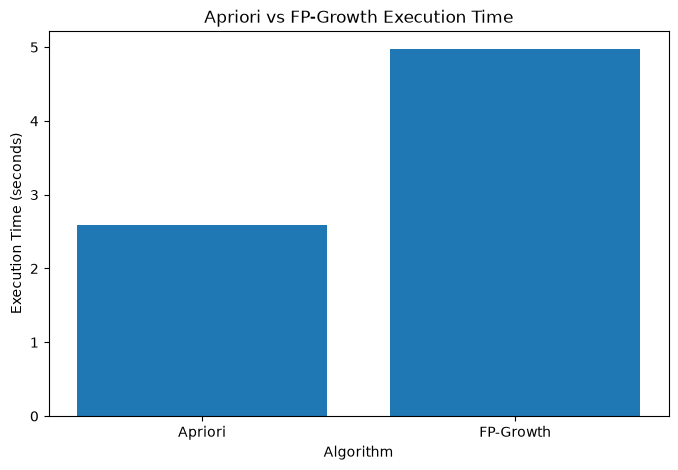

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Execution Time (seconds)"]
)

plt.title("Apriori vs FP-Growth Execution Time")
plt.xlabel("Algorithm")
plt.ylabel("Execution Time (seconds)")

plt.show()